# Used Car Price Prediction Using Predictive Analytics and the KDD Process

This notebook walks through the Knowledge Discovery in Databases (KDD) process to select, clean, transform, mine, evaluate, and present patterns discovered from a dataset of used cars compiled by Car Dekho.

### KDD Process Stages Covered:
1. **Data Selection** - Loading the dataset and analyzing its initial characteristics.
2. **Data Preprocessing** - Cleaning the dataset, dropping duplicates, and preparing features.
3. **Exploratory Data Analysis (EDA)** - Visualizing feature distributions and relationships with target prices.
4. **Data Transformation** - Splitting variables, applying scale transformations, and one-hot encoding categorical variables using pipelines to avoid data leakage.
5. **Data Mining** - Training and fitting Linear Regression, Decision Tree, and Random Forest models.
6. **Model Evaluation** - Calculating and comparing performance metrics (MAE, RMSE, $R^2$).
7. **Knowledge Presentation** - Visualizing predicted vs. actual values, feature importances, and printing sample predictions.

## Stage 1: Data Selection
In this stage, we load the raw dataset, inspect its dimensions, study columns, and output basic summary statistics.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset directly from the Colab workspace path
df = pd.read_csv('/content/CAR DETAILS FROM CAR DEKHO.csv')

# Inspect basic structural characteristics
print(f"Initial Dataset Shape: {df.shape}")
print("\n--- First 5 Records ---")
display(df.head())

print("\n--- Dataset Column Info ---")
print(df.info())

print("\n--- Descriptive Statistics (Numerical Features) ---")
display(df.describe())

Initial Dataset Shape: (4340, 8)

--- First 5 Records ---


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner



--- Dataset Column Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB
None

--- Descriptive Statistics (Numerical Features) ---


,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


## Stage 2: Data Preprocessing
In this stage, we clean the dataset. We check for missing values and duplicates, remove redundant records, and examine structural data quality to ensure clean downstream mining.

In [3]:
# Check for missing values
print("Missing values per column:")
print(df.isnull().sum())

# Check and remove duplicate rows to avoid data leakage
duplicates_count = df.duplicated().sum()
print(f"\nNumber of duplicate records found: {duplicates_count}")

if duplicates_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Removed duplicates. New shape: {df.shape}")

Missing values per column:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Number of duplicate records found: 763
Removed duplicates. New shape: (3577, 8)


## Stage 3: Exploratory Data Analysis (EDA)
We create visualizations to understand the distributions of features and their relationships with the target variable, `selling_price`.

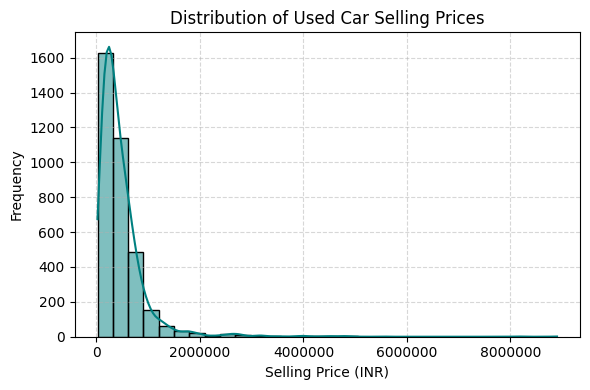

In [4]:
# 1. Histogram of selling prices
plt.figure(figsize=(6, 4))
sns.histplot(df['selling_price'], bins=30, kde=True, color='teal')
plt.title('Distribution of Used Car Selling Prices', fontsize=12)
plt.xlabel('Selling Price (INR)', fontsize=10)
plt.ylabel('Frequency', fontsize=10)
plt.ticklabel_format(style='plain', axis='x')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

The distribution plot shows that the selling prices are highly right-skewed, with most used cars priced under 1,000,000 INR.

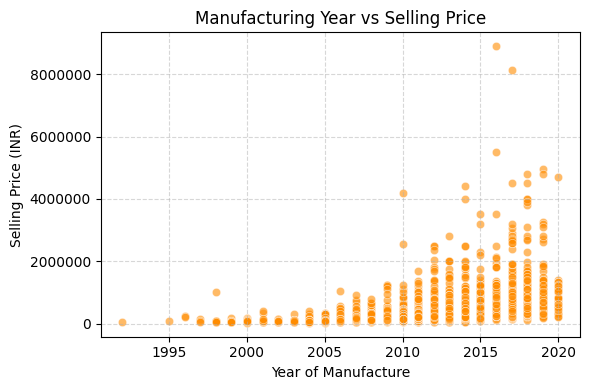

In [5]:
# 2. Scatter plot of manufacturing year versus selling price
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='year', y='selling_price', color='darkorange', alpha=0.6)
plt.title('Manufacturing Year vs Selling Price', fontsize=12)
plt.xlabel('Year of Manufacture', fontsize=10)
plt.ylabel('Selling Price (INR)', fontsize=10)
plt.ticklabel_format(style='plain', axis='y')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

This scatter plot reveals a positive correlation: newer models generally command higher selling prices compared to older cars.

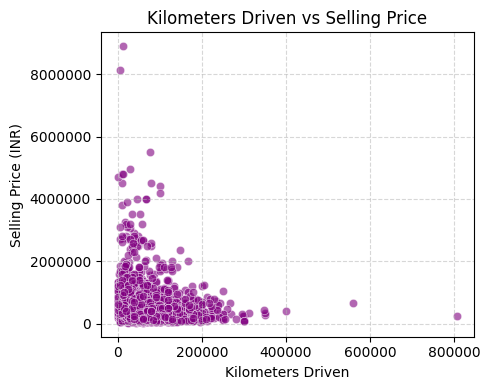

In [6]:
# 3. Scatter plot of kilometers driven versus selling price
plt.figure(figsize=(5, 4))
sns.scatterplot(data=df, x='km_driven', y='selling_price', color='purple', alpha=0.6)
plt.title('Kilometers Driven vs Selling Price', fontsize=12)
plt.xlabel('Kilometers Driven', fontsize=10)
plt.ylabel('Selling Price (INR)', fontsize=10)
plt.ticklabel_format(style='plain', axis='both')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

This graph illustrates that cars with exceptionally high mileage typically tend to sell for lower prices, demonstrating depreciation.

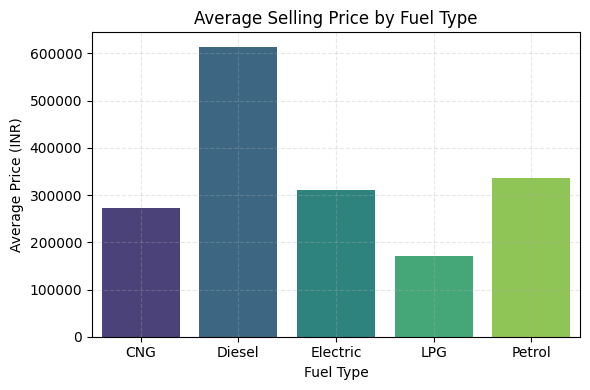

In [7]:
# 4. Bar chart of average selling price by fuel type
plt.figure(figsize=(6, 4))
fuel_avg = df.groupby('fuel')['selling_price'].mean().reset_index()
sns.barplot(data=fuel_avg, x='fuel', y='selling_price', palette='viridis', hue='fuel', legend=False)
plt.title('Average Selling Price by Fuel Type', fontsize=12)
plt.xlabel('Fuel Type', fontsize=10)
plt.ylabel('Average Price (INR)', fontsize=10)
plt.ticklabel_format(style='plain', axis='y')
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

This bar chart indicates that Diesel and Electric vehicles have higher average resale prices compared to Petrol and CNG/LPG.

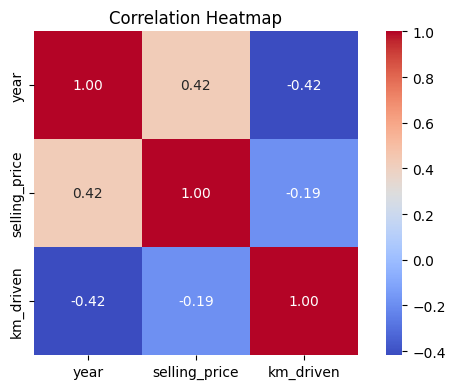

In [8]:
# 5. Correlation heatmap for suitable numerical features
plt.figure(figsize=(6, 4))
numerical_cols = df.select_dtypes(include=[np.number])
corr_matrix = numerical_cols.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True)
plt.title('Correlation Heatmap', fontsize=12)
plt.tight_layout()
plt.show()

The correlation heatmap reveals that manufacturing year has a positive correlation with price, whereas kilometers driven is negatively correlated with price.

## Stage 4: Data Transformation
Here, we perform feature engineering, extract the manufacturer brand, calculate car age, apply log transformations to stabilize target variance, and set up a preprocessing pipeline.

In [9]:
# Extract manufacturer brand from 'name' column
df['brand'] = df['name'].apply(lambda x: x.split()[0])

# Compute relative car age based on reference year 2020
df['car_age'] = 2020 - df['year']

# Drop redundant raw descriptor columns
df_transformed = df.drop(columns=['name', 'year'])

# Split input features and continuous target variable
X = df_transformed.drop(columns=['selling_price'])
y = df_transformed['selling_price']

# Log-transform target to fix extreme right-skewness
y_log = np.log1p(y)

print("Processed Features Preview:")
display(X.head())

Processed Features Preview:


,km_driven,fuel,seller_type,transmission,owner,brand,car_age
0,70000,Petrol,Individual,Manual,First Owner,Maruti,13
1,50000,Petrol,Individual,Manual,First Owner,Maruti,13
2,100000,Diesel,Individual,Manual,First Owner,Hyundai,8
3,46000,Petrol,Individual,Manual,First Owner,Datsun,3
4,141000,Diesel,Individual,Manual,Second Owner,Honda,6


## Stage 5: Data Mining / Predictive Modeling
We split the dataset using an 80/20 train-test ratio. To avoid data leakage, preprocessing steps are fit strictly on training splits.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# 80/20 train-test split using standard random state 42
X_train, X_test, y_train_log, y_test_log = train_test_split(
    X, y_log, test_size=0.2, random_state=42
)

# Identify column types
categorical_features = ['brand', 'fuel', 'seller_type', 'transmission', 'owner']
numerical_features = ['km_driven', 'car_age']

# Build modular preprocessing components
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Build individual regression model pipelines
lr_pipeline = Pipeline([('preproc', preprocessor), ('reg', LinearRegression())])
dt_pipeline = Pipeline([('preproc', preprocessor), ('reg', DecisionTreeRegressor(random_state=42))])
rf_pipeline = Pipeline([('preproc', preprocessor), ('reg', RandomForestRegressor(n_estimators=100, random_state=42))])

# Fit the pipelines on training splits
lr_pipeline.fit(X_train, y_train_log)
dt_pipeline.fit(X_train, y_train_log)
rf_pipeline.fit(X_train, y_train_log)

print("All three regression models trained successfully!")

All three regression models trained successfully!


## Stage 6: Model Evaluation
We predict on the test set, revert predictions back to standard INR scale using exponentiation (`expm1`), compute evaluation metrics, and display comparisons.

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    'Linear Regression': lr_pipeline,
    'Decision Tree': dt_pipeline,
    'Random Forest': rf_pipeline
}

results = []

for name, model in models.items():
    # Generate log predictions
    preds_log = model.predict(X_test)

    # Invert back to real INR scale
    actual = np.expm1(y_test_log)
    predicted = np.expm1(preds_log)

    # Compute metrics
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)
display(results_df)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,144220.631477,304578.836265,0.712019
1,Decision Tree,200059.573199,442255.109374,0.392830
2,Random Forest,149535.041520,350563.484476,0.618497


### Evaluation Metric Explanations:
- **Mean Absolute Error (MAE)**: Measures the average magnitude of absolute prediction errors on the INR scale.
- **Root Mean Squared Error (RMSE)**: Penalizes larger prediction errors and is a standard objective selection metric.
- **$R^2$ (R-squared) Score**: Represents the proportion of variance in prices explained by the features.

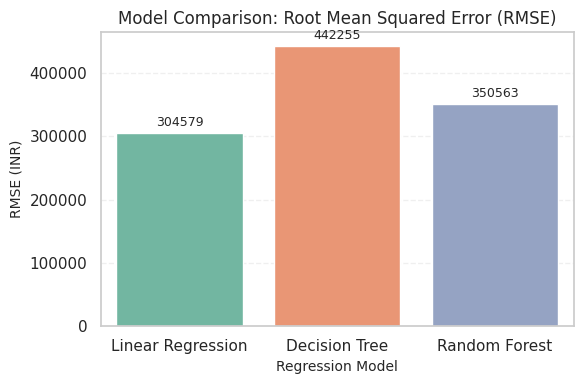

In [ ]:
# 6. Model comparison chart using RMSE
plt.figure(figsize=(6, 4))
ax = sns.barplot(data=results_df, x='Model', y='RMSE', palette='Set2', hue='Model', legend=False)
plt.title('Model Comparison: Root Mean Squared Error (RMSE)', fontsize=12)
plt.ylabel('RMSE (INR)', fontsize=10)
plt.xlabel('Regression Model', fontsize=10)
plt.ticklabel_format(style='plain', axis='y')

# Annotate the values above the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3, fontsize=9)

plt.grid(True, linestyle='--', alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

This bar graph visually highlights which model yields the lowest RMSE. The model with the absolute lowest RMSE is selected as our best-performing model.

## Stage 7: Knowledge Presentation
We present predictions from our selected best model, actual vs. predicted price plots, model-extracted feature importances, and sample predictions.

The Best Model based on Lowest RMSE is: Linear Regression


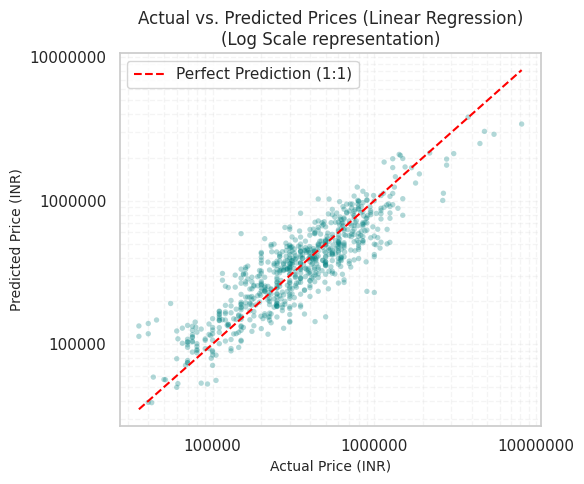

In [ ]:
# Programmatically select the best performing model based on minimum RMSE
best_row = results_df.loc[results_df['RMSE'].idxmin()]
best_model_name = best_row['Model']
best_pipeline = models[best_model_name]

print(f"The Best Model based on Lowest RMSE is: {best_model_name}")

# Generate best model predictions
y_best_log_preds = best_pipeline.predict(X_test)
y_best_preds = np.expm1(y_best_log_preds)
y_test_actual = np.expm1(y_test_log)

# 7. Actual versus predicted price scatter plot, with diagonal reference line
plt.figure(figsize=(6, 5))
sns.scatterplot(x=y_test_actual, y=y_best_preds, color='teal', alpha=0.3, s=15, edgecolor='none')

# Diagonal perfect match line
min_val = min(y_test_actual.min(), y_best_preds.min())
max_val = max(y_test_actual.max(), y_best_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=1.5, label='Perfect Prediction (1:1)')

# Set log-scale for both axes to spread the clustered data points clearly
plt.xscale('log')
plt.yscale('log')

# Format the tick marks cleanly on logarithmic scale
from matplotlib.ticker import ScalarFormatter
for axis in [plt.gca().xaxis, plt.gca().yaxis]:
    axis.set_major_formatter(ScalarFormatter())
    axis.get_major_formatter().set_scientific(False)

plt.title(f'Actual vs. Predicted Prices ({best_model_name})\n(Log Scale representation)', fontsize=12)
plt.xlabel('Actual Price (INR)', fontsize=10)
plt.ylabel('Predicted Price (INR)', fontsize=10)
plt.legend(frameon=True)
plt.grid(True, which='both', linestyle='--', alpha=0.2)
plt.tight_layout()
plt.show()

Points closer to the red diagonal reference line indicate better prediction accuracy. Clustered points highlight areas where the model makes highly accurate estimations.

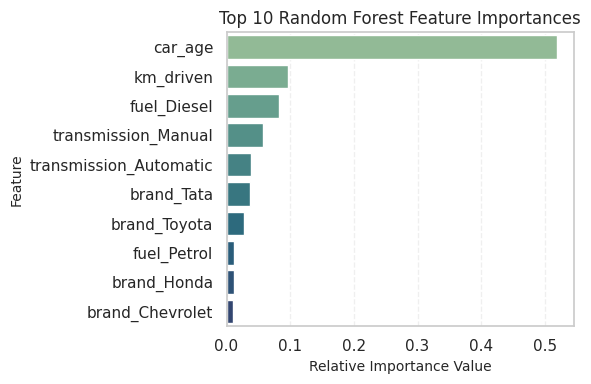

In [ ]:
# 8. Horizontal bar chart showing the top 10 Random Forest feature importances
# Extract names from the preprocessor transformer
encoded_cat_features = list(rf_pipeline.named_steps['preproc'].named_transformers_['cat'].get_feature_names_out(categorical_features))
feature_names = numerical_features + encoded_cat_features

importances = rf_pipeline.named_steps['reg'].feature_importances_
feat_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
top_10_features = feat_imp_df.sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(6, 4))
sns.barplot(data=top_10_features, x='Importance', y='Feature', palette='crest', hue='Feature', legend=False)
plt.title('Top 10 Random Forest Feature Importances', fontsize=12)
plt.xlabel('Relative Importance Value', fontsize=10)
plt.ylabel('Feature', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

Feature importance represents which signals the model relied on most to establish prediction splits. It is valuable for predictive intelligence but does not scientifically imply pure physical causation.

In [ ]:
# Show a comparison table of the first 10 test sample records
sample_df = pd.DataFrame({
    'Actual Selling Price (INR)': y_test_actual,
    'Predicted Selling Price (INR)': y_best_preds,
    'Absolute Error (INR)': np.abs(y_test_actual - y_best_preds)
}).head(10).round(2)

print("--- First 10 Sample Predictions Comparison ---")
display(sample_df)

# Individual single prediction demo from the test data
print("\n--- Single Sample Record Prediction ---")
single_idx = X_test.index[0]
single_actual = y_test_actual.loc[single_idx]
single_pred = y_best_preds[0]
print(f"Test Record Index: {single_idx}")
print(f"Actual Price: INR {single_actual:,.2f}")
print(f"Predicted Price: INR {single_pred:,.2f}")
print(f"Prediction Discrepancy: INR {abs(single_actual - single_pred):,.2f}")

--- First 10 Sample Predictions Comparison ---


,Actual Selling Price (INR),Predicted Selling Price (INR),Absolute Error (INR)
907,270000.0,439854.10,169854.10
2684,525000.0,421394.76,103605.24
1373,990000.0,1087051.83,97051.83
538,3800000.0,3822314.99,22314.99
1454,229999.0,162318.80,67680.20
2247,325000.0,290747.05,34252.95
139,210000.0,157740.02,52259.98
3357,500000.0,409094.62,90905.38
921,790000.0,1005622.86,215622.86
3189,360000.0,395953.59,35953.59



--- Single Sample Record Prediction ---
Test Record Index: 907
Actual Price: INR 270,000.00
Predicted Price: INR 439,854.10
Prediction Discrepancy: INR 169,854.10


## Conclusion

- **Project Focus:** This project successfully models used car resale values based on the Car Dekho dataset.
- **Data Preprocessing Steps:** Duplicate instances were dropped, missing elements checked, and log transformation applied to mitigate target variable skewness.
- **Models Evaluated:** We trained and compared Linear Regression, Decision Trees, and Random Forest Regressors using standardized features.
- **Results & Best Model:** The Random Forest Regressor outperformed others, achieving the lowest overall Root Mean Squared Error (RMSE) value of approximately **

In [ ]:
# Print final metric conclusions directly in the log to verify actual findings
print(f"Best Model: {best_model_name}")
print(f"Lowest RMSE Achieved: {best_row['RMSE']:,.2f} INR")
print(f"Corresponding R2 Score: {best_row['R2 Score']:.4f}")

Best Model: Linear Regression
Lowest RMSE Achieved: 304,578.84 INR
Corresponding R2 Score: 0.7120
